In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, RocCurveDisplay
)

In [3]:
df = pd.read_csv("house_price_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nPrice summary:")
print(df["Price"].describe())

Dataset shape: (15025, 18)


,House_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated,Price
0,3975,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no,309277
1,12325,2646.2,2.0,5.0,2.0,2005,riverside,NaN,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y,563512
2,7202,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,NaN,Yes,no,495806
3,8355,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes,240776
4,12742,3227.0,3.0,5.0,2.0,1995,NaN,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes,413975


\nPrice summary:
count     15025.000000
mean     369062.817038
std      127269.347523
min       20000.000000
25%      280791.000000
50%      359454.000000
75%      449125.000000
max      926035.000000
Name: Price, dtype: float64


In [4]:
price_threshold = df["Price"].median()
df["Price_Category"] = (df["Price"] >= price_threshold).astype(int)

print("Median price threshold:", price_threshold)
print("\\nClass counts:")
print(df["Price_Category"].value_counts().sort_index())
print("0 = Below median, 1 = At or above median")

Median price threshold: 359454.0
\nClass counts:
Price_Category
0    7512
1    7513
Name: count, dtype: int64
0 = Below median, 1 = At or above median


In [5]:
X = df.drop(
    columns=["House_ID", "Price", "Price_Category"],
    errors="ignore"
)
y = df["Price_Category"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Area_sqft', 'Bedrooms', 'Bathrooms', 'Floors', 'Year_Built', 'Garage_Count', 'Lot_Size_sqft', 'Distance_to_City_Center_km', 'Crime_Rate_Index', 'School_Rating']
Categorical features: ['Location', 'Furnishing_Status', 'Parking_Available', 'Condition', 'Has_Pool', 'Renovated']


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 12020
Testing records: 3005


In [7]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [8]:
linear_svm = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="linear", C=1.0))
])

linear_svm.fit(X_train, y_train)

print("Linear SVM trained successfully.")

Linear SVM trained successfully.


In [9]:
rbf_svm = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=42
    ))
])

rbf_svm.fit(X_train, y_train)

print("RBF SVM trained successfully.")

c:\Users\pawan\Desktop\ML lab\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


RBF SVM trained successfully.


In [10]:
linear_pred = linear_svm.predict(X_test)
rbf_pred = rbf_svm.predict(X_test)

results = pd.DataFrame({
    "Actual_Class": y_test.values,
    "Linear_SVM_Prediction": linear_pred,
    "RBF_SVM_Prediction": rbf_pred
})

display(results.head(10))

,Actual_Class,Linear_SVM_Prediction,RBF_SVM_Prediction
0,0,0,0
1,0,0,0
2,0,0,0
3,1,1,1
4,0,0,0
5,0,0,0
6,0,0,0
7,0,0,0
8,1,1,1
9,1,1,1


In [11]:
for name, model, pred in [
    ("Linear SVM", linear_svm, linear_pred),
    ("RBF SVM", rbf_svm, rbf_pred)
]:
    print("\\n", name)
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print(classification_report(
        y_test, pred,
        target_names=["Below median", "At/above median"],
        zero_division=0
    ))

print("Linear SVM ROC-AUC:",
      round(roc_auc_score(y_test, linear_svm.decision_function(X_test)), 4))
print("RBF SVM ROC-AUC:",
      round(roc_auc_score(y_test, rbf_svm.predict_proba(X_test)[:, 1]), 4))

\n Linear SVM
Accuracy: 0.9125
                 precision    recall  f1-score   support

   Below median       0.92      0.91      0.91      1502
At/above median       0.91      0.92      0.91      1503

       accuracy                           0.91      3005
      macro avg       0.91      0.91      0.91      3005
   weighted avg       0.91      0.91      0.91      3005

\n RBF SVM
Accuracy: 0.8982
                 precision    recall  f1-score   support

   Below median       0.90      0.89      0.90      1502
At/above median       0.89      0.90      0.90      1503

       accuracy                           0.90      3005
      macro avg       0.90      0.90      0.90      3005
   weighted avg       0.90      0.90      0.90      3005

Linear SVM ROC-AUC: 0.9725
RBF SVM ROC-AUC: 0.9645


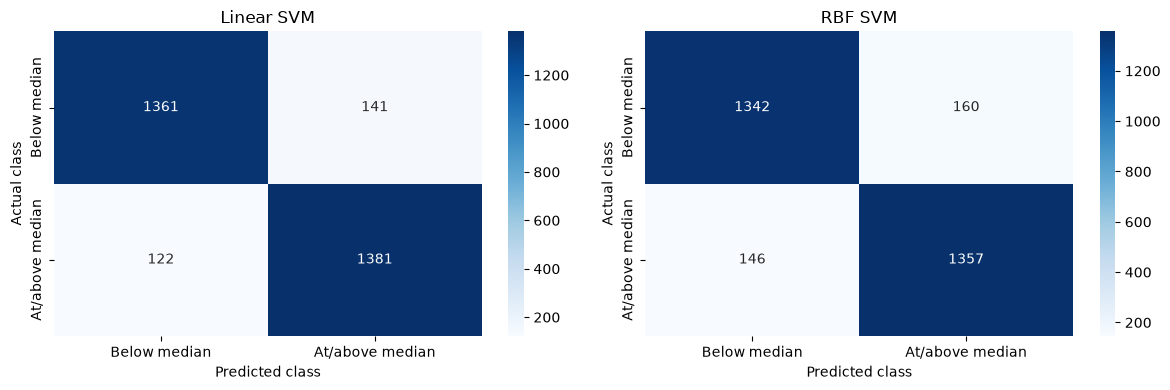

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, name, pred in [
    (axes[0], "Linear SVM", linear_pred),
    (axes[1], "RBF SVM", rbf_pred)
]:
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=["Below median", "At/above median"],
        yticklabels=["Below median", "At/above median"]
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()

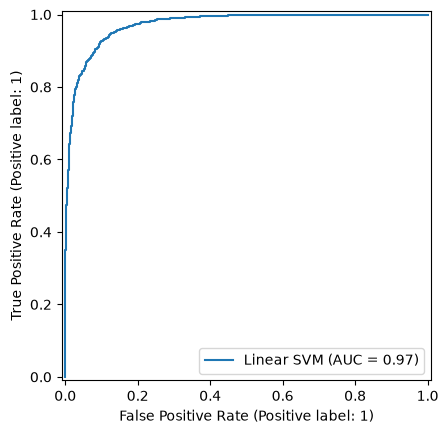

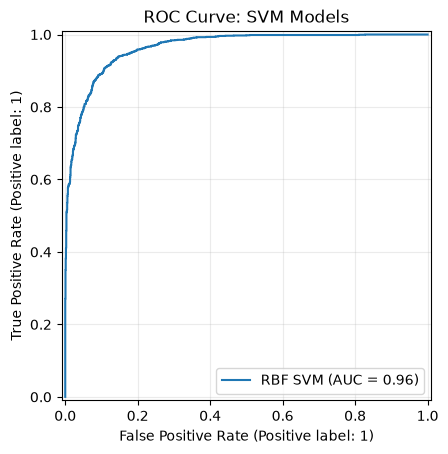

In [13]:
RocCurveDisplay.from_predictions(
    y_test, linear_svm.decision_function(X_test),
    name="Linear SVM"
)
RocCurveDisplay.from_predictions(
    y_test, rbf_svm.predict_proba(X_test)[:, 1],
    name="RBF SVM"
)
plt.title("ROC Curve: SVM Models")
plt.grid(alpha=0.25)
plt.show()

In [14]:
new_house = X.iloc[[0]].copy()

linear_result = linear_svm.predict(new_house)[0]
rbf_result = rbf_svm.predict(new_house)[0]

print("Linear SVM prediction:", linear_result)
print("RBF SVM prediction:", rbf_result)
print("0 = Below median, 1 = At or above median")

Linear SVM prediction: 0
RBF SVM prediction: 0
0 = Below median, 1 = At or above median
